# 08 · Caso Yuna: lluvia y memoria arriba → presa de Hatillo → inundación abajo

Hipótesis de investigación (no causalidad demostrada): la lluvia y el estado antecedente del Alto Yuna (IMERG · SMAP L4 · GLDAS) → escorrentía y respuesta del río → operación de Hatillo → inundación en el Bajo Yuna. Giro «Mentalist»: la correlación entre la humedad de cabecera y las inundaciones de abajo podría cambiar por la operación del embalse. Encontrar eso es un resultado válido.

Cada variable lleva su clase: **OBSERVACIÓN** (JRC GSW), **RECUPERACIÓN SATELITAL** (IMERG, CHIRPS), **MODELO CON ASIMILACIÓN** (SMAP L4), **MODELO FORZADO** (GLDAS), **SIMULACIÓN HIDROLÓGICA** (GEOGLOWS v2).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display
ROOT = Path.cwd()
while not (ROOT / "results" / "yuna").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RES, FIG = ROOT / "results" / "yuna", ROOT / "figures" / "yuna"
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 80)
def fig(nombre, ancho=900):
    display(Image(filename=str(FIG / f"{nombre}.png"), width=ancho))

## 1 · La cuenca y qué drena dónde

HydroBASINS v1c nivel 10 + HydroRIVERS (Lehner y Grill 2013).

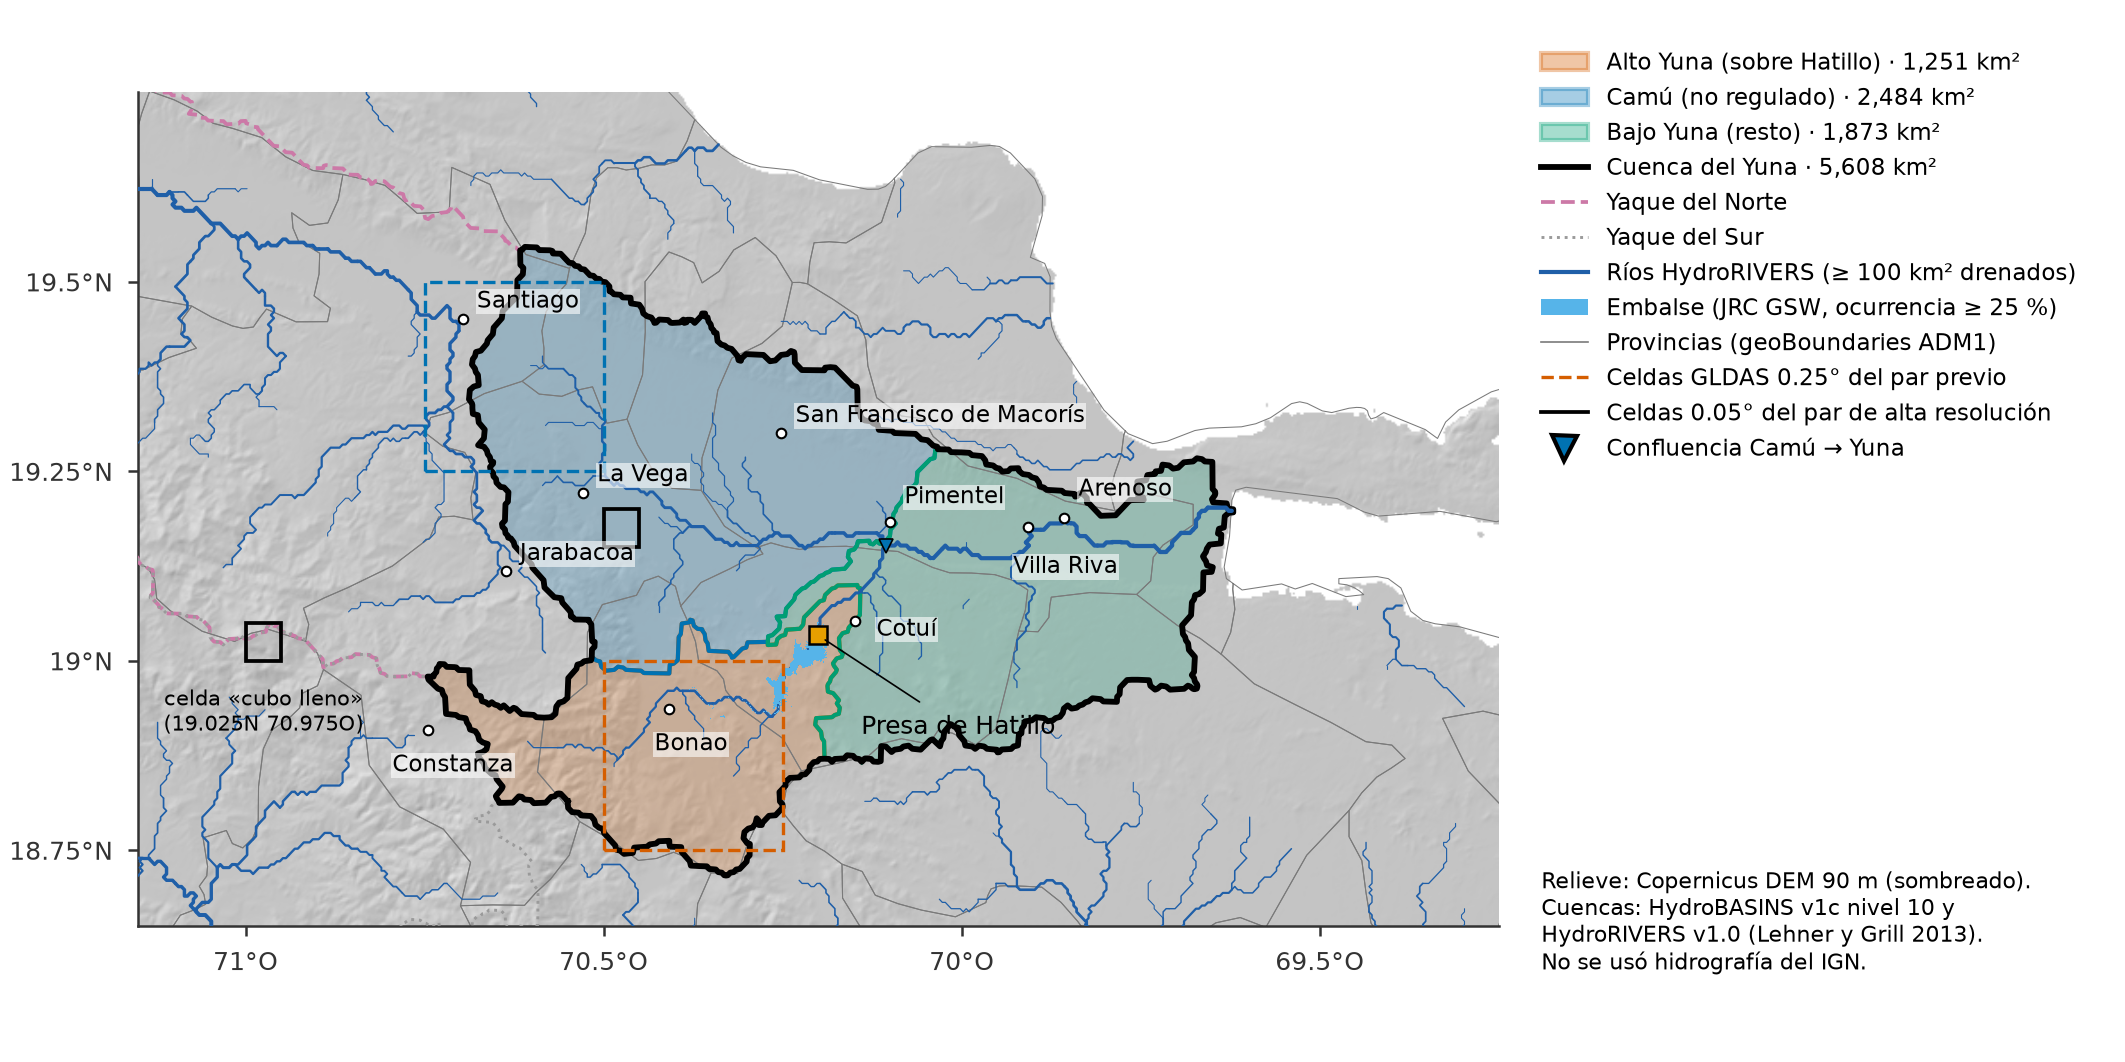

In [2]:
fig("fig_y1_cuenca_yuna")

In [3]:
cu = json.loads((RES / "cuencas_resumen.json").read_text(encoding="utf-8"))
print(json.dumps({k: cu[k] for k in ("areas_km2", "hatillo", "camu", "salidas")}, ensure_ascii=False, indent=1))

{
 "areas_km2": {
  "yuna": 5608.0,
  "alto_hatillo": 1250.9,
  "camu": 2484.2,
  "bajo_yuna": 1872.9,
  "Yaque del Norte": 7057.5,
  "Yaque del Sur": 8258.5,
  "Ozama": 3390.7
 },
 "hatillo": {
  "poligono_lev10": 7100842890,
  "UP_AREA_lev10_km2": 1256.5,
  "hydrorivers_tramo": 70892697,
  "hydrorivers_UPLAND_km2": 1256.5,
  "hydrorivers_caudal_medio_m3s": 24.035,
  "dist_tramo_cortina_km": 0.26
 },
 "camu": {
  "tramo_final": 70891553,
  "UPLAND_km2": 2495.4,
  "caudal_medio_m3s_hydrorivers": 38.386,
  "confluencia_lonlat": [
   -70.1063,
   19.1521
  ],
  "tramo_receptor": 70891554,
  "UPLAND_receptor_km2": 4210.8,
  "poligono_lev10": 7100842370
 },
 "salidas": {
  "Yuna": {
   "HYBAS_ID": 7100072320,
   "UP_AREA_km2": 5494.8,
   "centroide": [
    19.2011,
    -69.6859
   ]
  },
  "Yaque del Norte": {
   "HYBAS_ID": 7100072120,
   "UP_AREA_km2": 7089.3,
   "centroide": [
    19.8038,
    -71.6281
   ]
  },
  "Yaque del Sur": {
   "HYBAS_ID": 7100072760,
   "UP_AREA_km2": 5218.0,
 

In [4]:
pd.read_csv(RES / "que_drena_donde.csv")[["punto", "celda_grados", "frac_Yuna", "frac_Yaque del Norte",
    "frac_Yaque del Sur", "frac_alto_hatillo", "frac_camu", "frac_bajo_yuna", "salida_cuenca"]]

,punto,celda_grados,frac_Yuna,frac_Yaque del Norte,frac_Yaque del Sur,frac_alto_hatillo,frac_camu,frac_bajo_yuna,salida_cuenca
0,celda_GLDAS_MonsenorNouel_18.875_-70.375,0.25,0.955,0.000,0.000,0.934,0.02,0.0,Yuna
1,celda_GLDAS_Santiago_LaVega_19.375_-70.625,0.25,0.650,0.350,0.000,0.000,0.65,0.0,Yuna
2,celda_HR_cordillera_19.025_-70.975,0.05,0.000,0.222,0.778,0.000,0.00,0.0,Yaque del Sur
3,celda_HR_LaVega_19.175_-70.475,0.05,1.000,0.000,0.000,0.000,1.00,0.0,Yuna
4,Bonao,NaN,1.000,0.000,0.000,1.000,0.00,0.0,Yuna
5,La Vega (ciudad),NaN,1.000,0.000,0.000,0.000,1.00,0.0,Yuna
6,Santiago (ciudad),NaN,0.000,1.000,0.000,0.000,0.00,0.0,Yaque del Norte
7,Cotuí,NaN,1.000,0.000,0.000,0.000,0.00,1.0,Yuna
8,San Francisco de Macorís,NaN,1.000,0.000,0.000,0.000,1.00,0.0,Yuna
9,Villa Riva,NaN,1.000,0.000,0.000,0.000,0.00,1.0,Yuna


## 2 · Catálogo de eventos (registro documental, cada uno con URL)

In [5]:
cat = pd.read_csv(RES / "catalogo_eventos.csv")
display(cat["zona"].value_counts())
cat[["id", "inicio", "fin", "precision", "zona", "confianza", "n_fuentes", "n_fuentes_leidas", "usable_backtest", "motivo_exclusion"]]

zona
bajo_yuna                      12
hatillo_operacion              10
cuenca_general                  3
alto_yuna                       1
fuera_yuna_precedente_presa     1
Name: count, dtype: int64

,id,inicio,fin,precision,zona,confianza,n_fuentes,n_fuentes_leidas,usable_backtest,motivo_exclusion
0,2003-11,2003-11-14,2003-11-26,semana,bajo_yuna,alta,6,1.0,True,NaN
1,2007-10,2007-10-28,2007-11-04,semana,bajo_yuna,alta,4,3.0,True,NaN
2,2007-12,2007-12-11,2007-12-14,dia,bajo_yuna,alta,4,3.0,True,NaN
3,2011-06,2011-05-28,2011-06-04,semana,alto_yuna,media,1,1.0,True,NaN
4,2012-08,2012-08-24,2012-08-28,dia,cuenca_general,media,3,1.0,True,NaN
5,2012-10,2012-10-23,2012-10-27,dia,cuenca_general,baja,2,1.0,True,NaN
6,2016-11,2016-10-29,2016-11-24,semana,bajo_yuna,alta,5,3.0,True,NaN
7,2017-04,2017-04-19,2017-05-02,semana,bajo_yuna,alta,4,2.0,True,NaN
8,2017-09,2017-09-21,2017-09-26,dia,bajo_yuna,alta,4,3.0,True,NaN
9,2020-07,2020-07-30,2020-08-02,dia,bajo_yuna,media,3,2.0,True,NaN


In [6]:
cat.loc[cat["hatillo_menciones"].fillna("").str.len() > 0, ["id", "hatillo_menciones"]]

,id,hatillo_menciones
0,2003-11,Charter (27-nov-2003): alerta roja y temor de que las presas de Monción y Ha...
1,2007-10,No se encontró mención específica de vertido/compuertas de Hatillo en Noel. ...
2,2007-12,Ninguna fuente encontrada menciona vertido de Hatillo en Olga (Expansión no ...
3,2011-06,Solo acceso vial a la presa cortado; no dice si vertía.
6,2016-11,Dominican Today 16-nov-2016: 'Hatillo dam has the highest level at 120% of c...
7,2017-04,DR1 25-abr-2017 (citando Listín 24-abr): embalse de Hatillo en 89.7 m; direc...
8,2017-09,"22-sep-2017 INDRHI: Hatillo cota 87.57 msnm (+0.30 m/día), Qentrada 221.76 m..."
10,2022-09,"Hatillo vertiendo el 19-20 sep 2022 (COE Informe 5, enlace arriba); INDRHI: ..."
11,2023-11,"21-nov-2023 INDRHI: Hatillo a 87.51 msnm (>100%), vertiendo con Qsalida 167...."
12,2024-11,IFRC MDRDO018 dice genéricamente que 'the opening of dam floodgates increase...


## 3 · Agua observada (JRC GSW mensual, Landsat) y el embalse de Hatillo

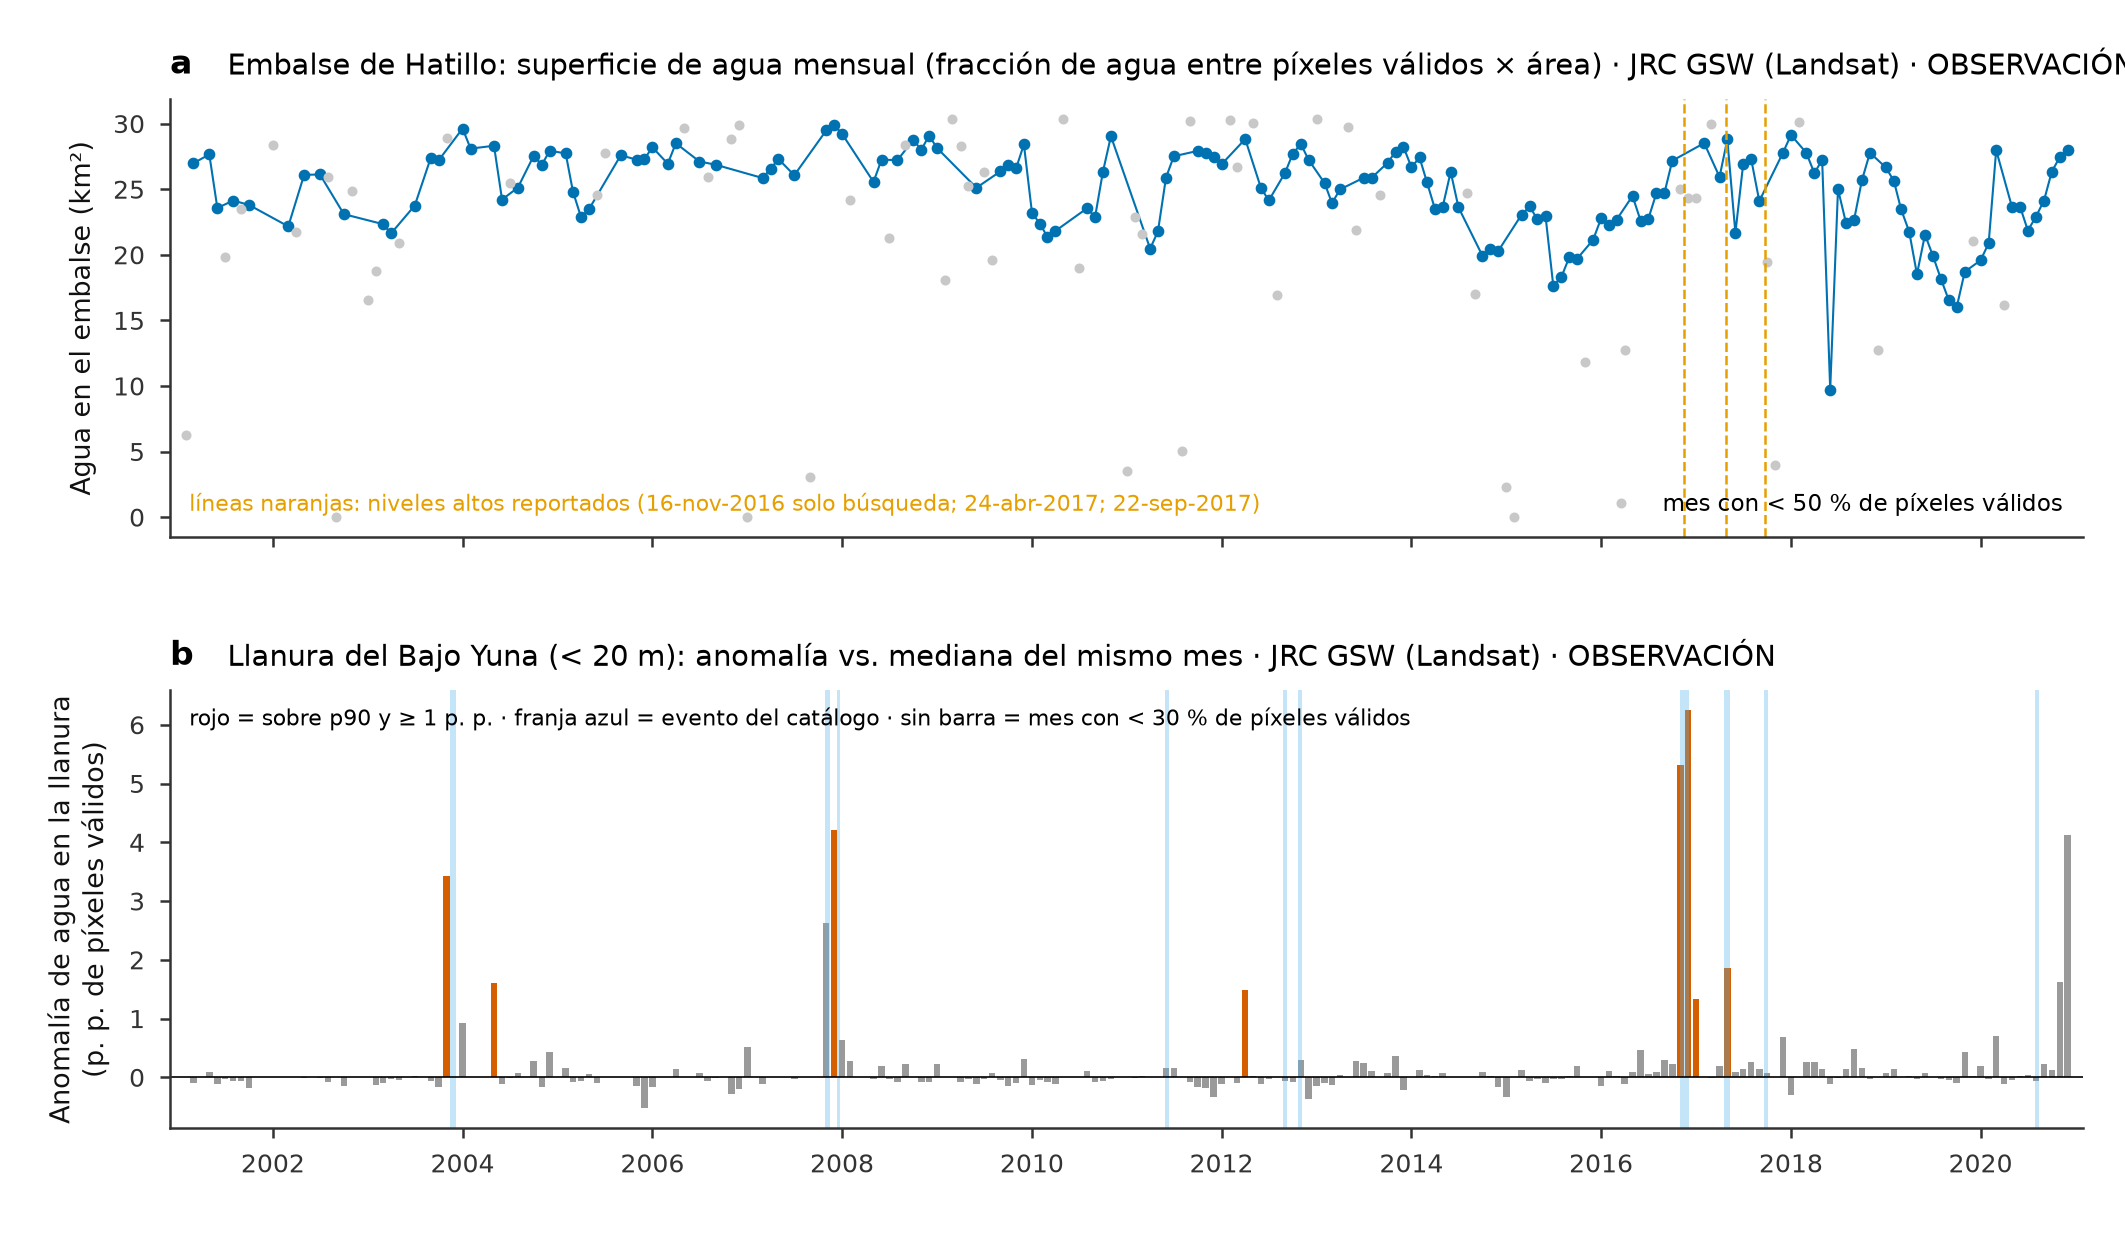

In [7]:
fig("fig_y2_agua_observada_gsw")

In [8]:
print(json.loads((RES / "gsw_mascaras.json").read_text()))

{'embalse_px': 41768, 'embalse_km2_max_posible': 30.354761263231552, 'llanura_px': 515833, 'llanura_km2': 374.87999345662996, 'meses_gsw': 240}


## 3b · Inundación observada con MODIS MCDWD_L3 (2003-2025)

Compuesto de 2 días (Flood_2Day_250m): 0 sin agua · 1 agua de referencia · 2 inundación recurrente · 3 inundación inusual · 255 datos insuficientes (nubes). Inundación observada = clase 3 por encima del p95 de días secos de referencia y ≥ 2 km². Sin días visibles = indeterminado, no «sin inundación».

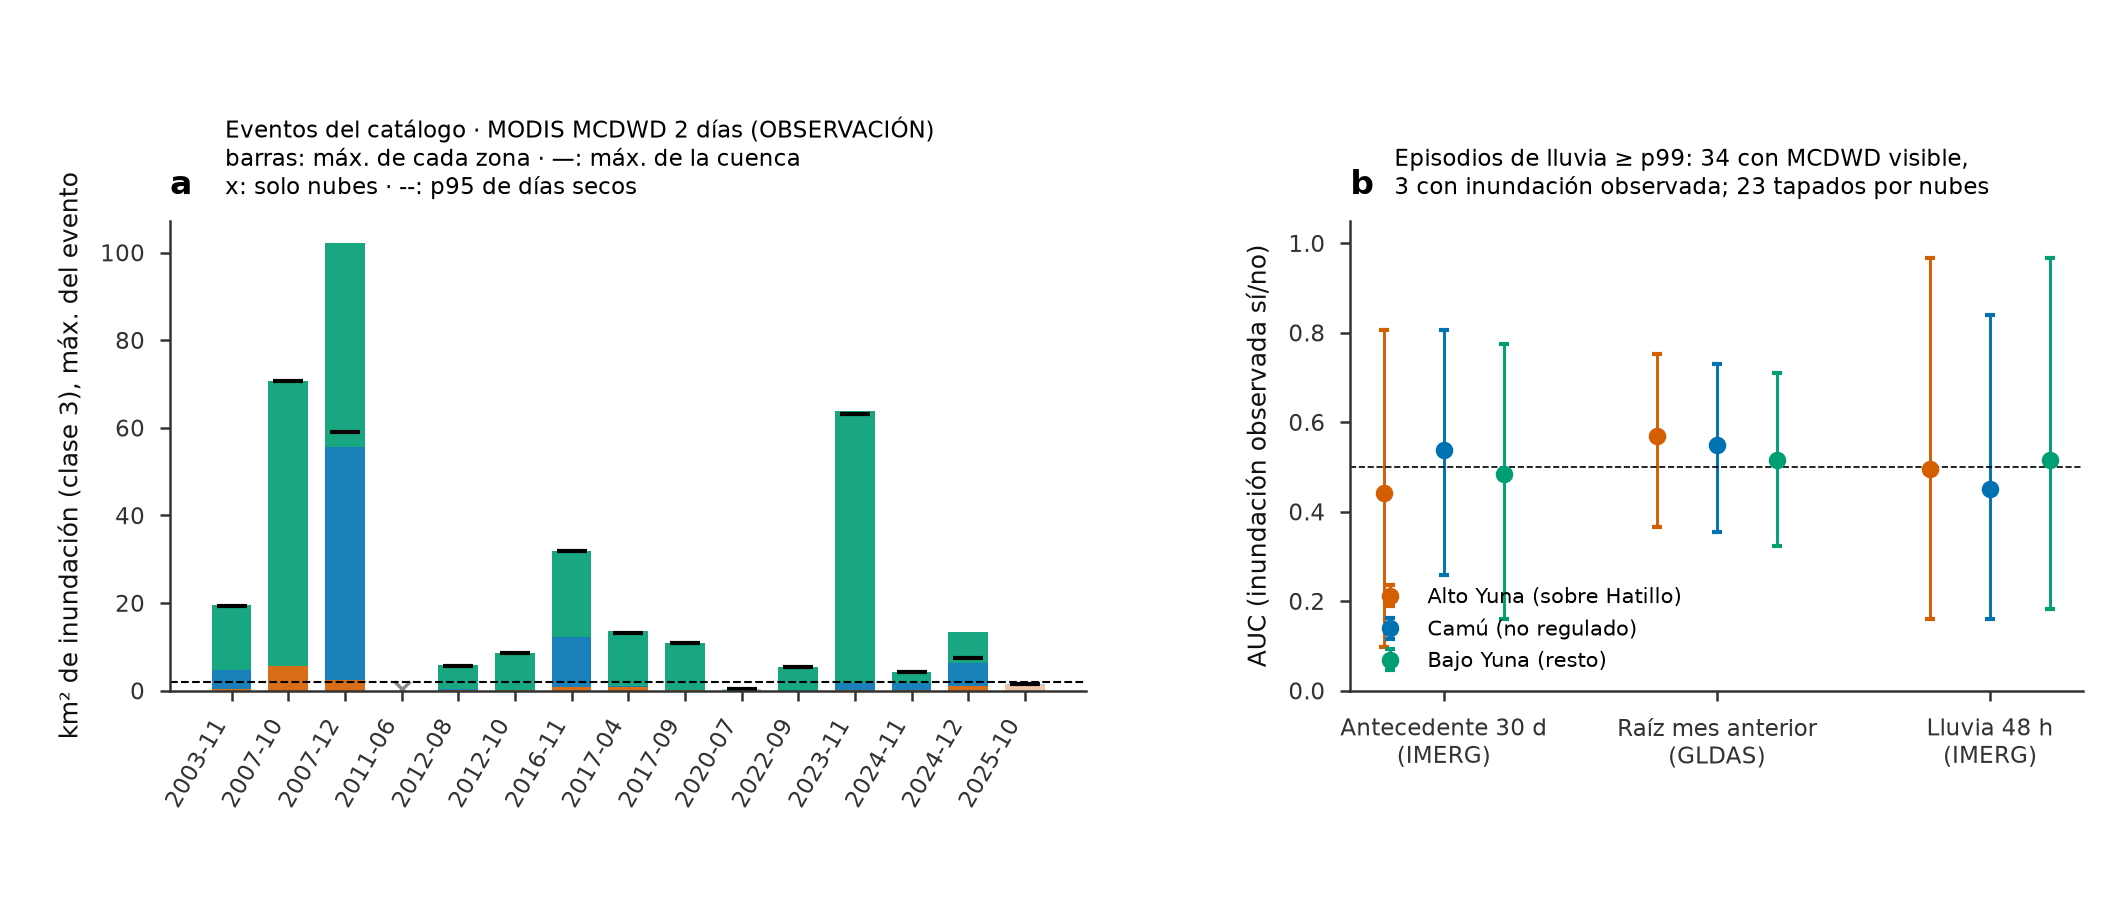

In [9]:
fig("fig_y6_inundacion_observada_mcdwd")

In [10]:
r = json.loads((RES / "mcdwd_resumen.json").read_text(encoding="utf-8"))
print(json.dumps({k: r[k] for k in ("n_dias", "insuf_media_yuna_2d", "MAX_INSUF", "MIN_KM2")}, indent=1))
pd.read_csv(RES / "mcdwd_por_evento.csv")[["id", "observa", "inund_km2_max_yuna", "anomalia_km2_yuna", "insuf_min_yuna", "n_obs_yuna", "n_dias"]]

{
 "n_dias": 209,
 "insuf_media_yuna_2d": 0.5749165150925896,
 "MAX_INSUF": 0.8,
 "MIN_KM2": 2.0
}


,id,observa,inund_km2_max_yuna,anomalia_km2_yuna,insuf_min_yuna,n_obs_yuna,n_dias
0,2003-11,True,19.228510,19.127573,0.230409,4,7
1,2007-10,True,70.756878,70.655941,0.324516,1,5
2,2007-12,True,59.048179,58.947242,0.073375,3,5
3,2011-06,NaN,NaN,NaN,0.995317,0,5
4,2012-08,True,5.652475,5.551538,0.242058,2,5
5,2012-10,True,8.579650,8.478713,0.001906,3,5
6,2016-11,True,31.795173,31.694236,0.147291,6,12
7,2017-04,True,13.071349,12.970412,0.077964,3,8
8,2017-09,True,10.951671,10.850734,0.294677,3,5
9,2020-07,False,0.454217,0.353280,0.086012,4,5


In [11]:
pd.read_csv(RES / "mcdwd_meses_gsw_sin_evento.csv")[["mes", "observa", "inund_km2_max_yuna", "insuf_min_yuna"]]

,mes,observa,inund_km2_max_yuna,insuf_min_yuna
0,2004-05,True,2.069210,0.214030
1,2012-04,False,1.211245,0.368358
2,2017-01,True,8.529181,0.069916


In [12]:
pd.read_csv(RES / "backtest_verificacion_mcdwd.csv")

,id,mcdwd_observa,mcdwd_inund_km2_max_yuna,mcdwd_insuf_min_yuna,a_lluvia100,a2_lluvia_media_cal,c_antecedente,b_lluvia100_y_ant_p90,b2_umbral_rebajado_si_humedo,b3_lluvia100_o_rebajado_gldas,b4_lluvia100_o_rebajado_smap
0,2003-11,True,19.228510,0.230409,False,False,True,False,True,False,False
1,2007-10,True,70.756878,0.324516,True,True,True,True,True,True,True
2,2007-12,True,59.048179,0.073375,True,True,True,True,True,True,True
3,2011-06,NaN,NaN,0.995317,True,False,False,False,True,True,True
4,2012-08,True,5.652475,0.242058,True,False,False,False,True,True,True
5,2012-10,True,8.579650,0.001906,True,True,False,True,True,True,True
6,2016-11,True,31.795173,0.147291,True,False,True,True,True,True,True
7,2017-04,True,13.071349,0.077964,True,False,False,False,True,True,True
8,2017-09,True,10.951671,0.294677,True,False,False,False,True,True,True
9,2020-07,False,0.454217,0.086012,True,False,False,False,True,True,True


## 4 · Paneles por evento (mismas escalas)

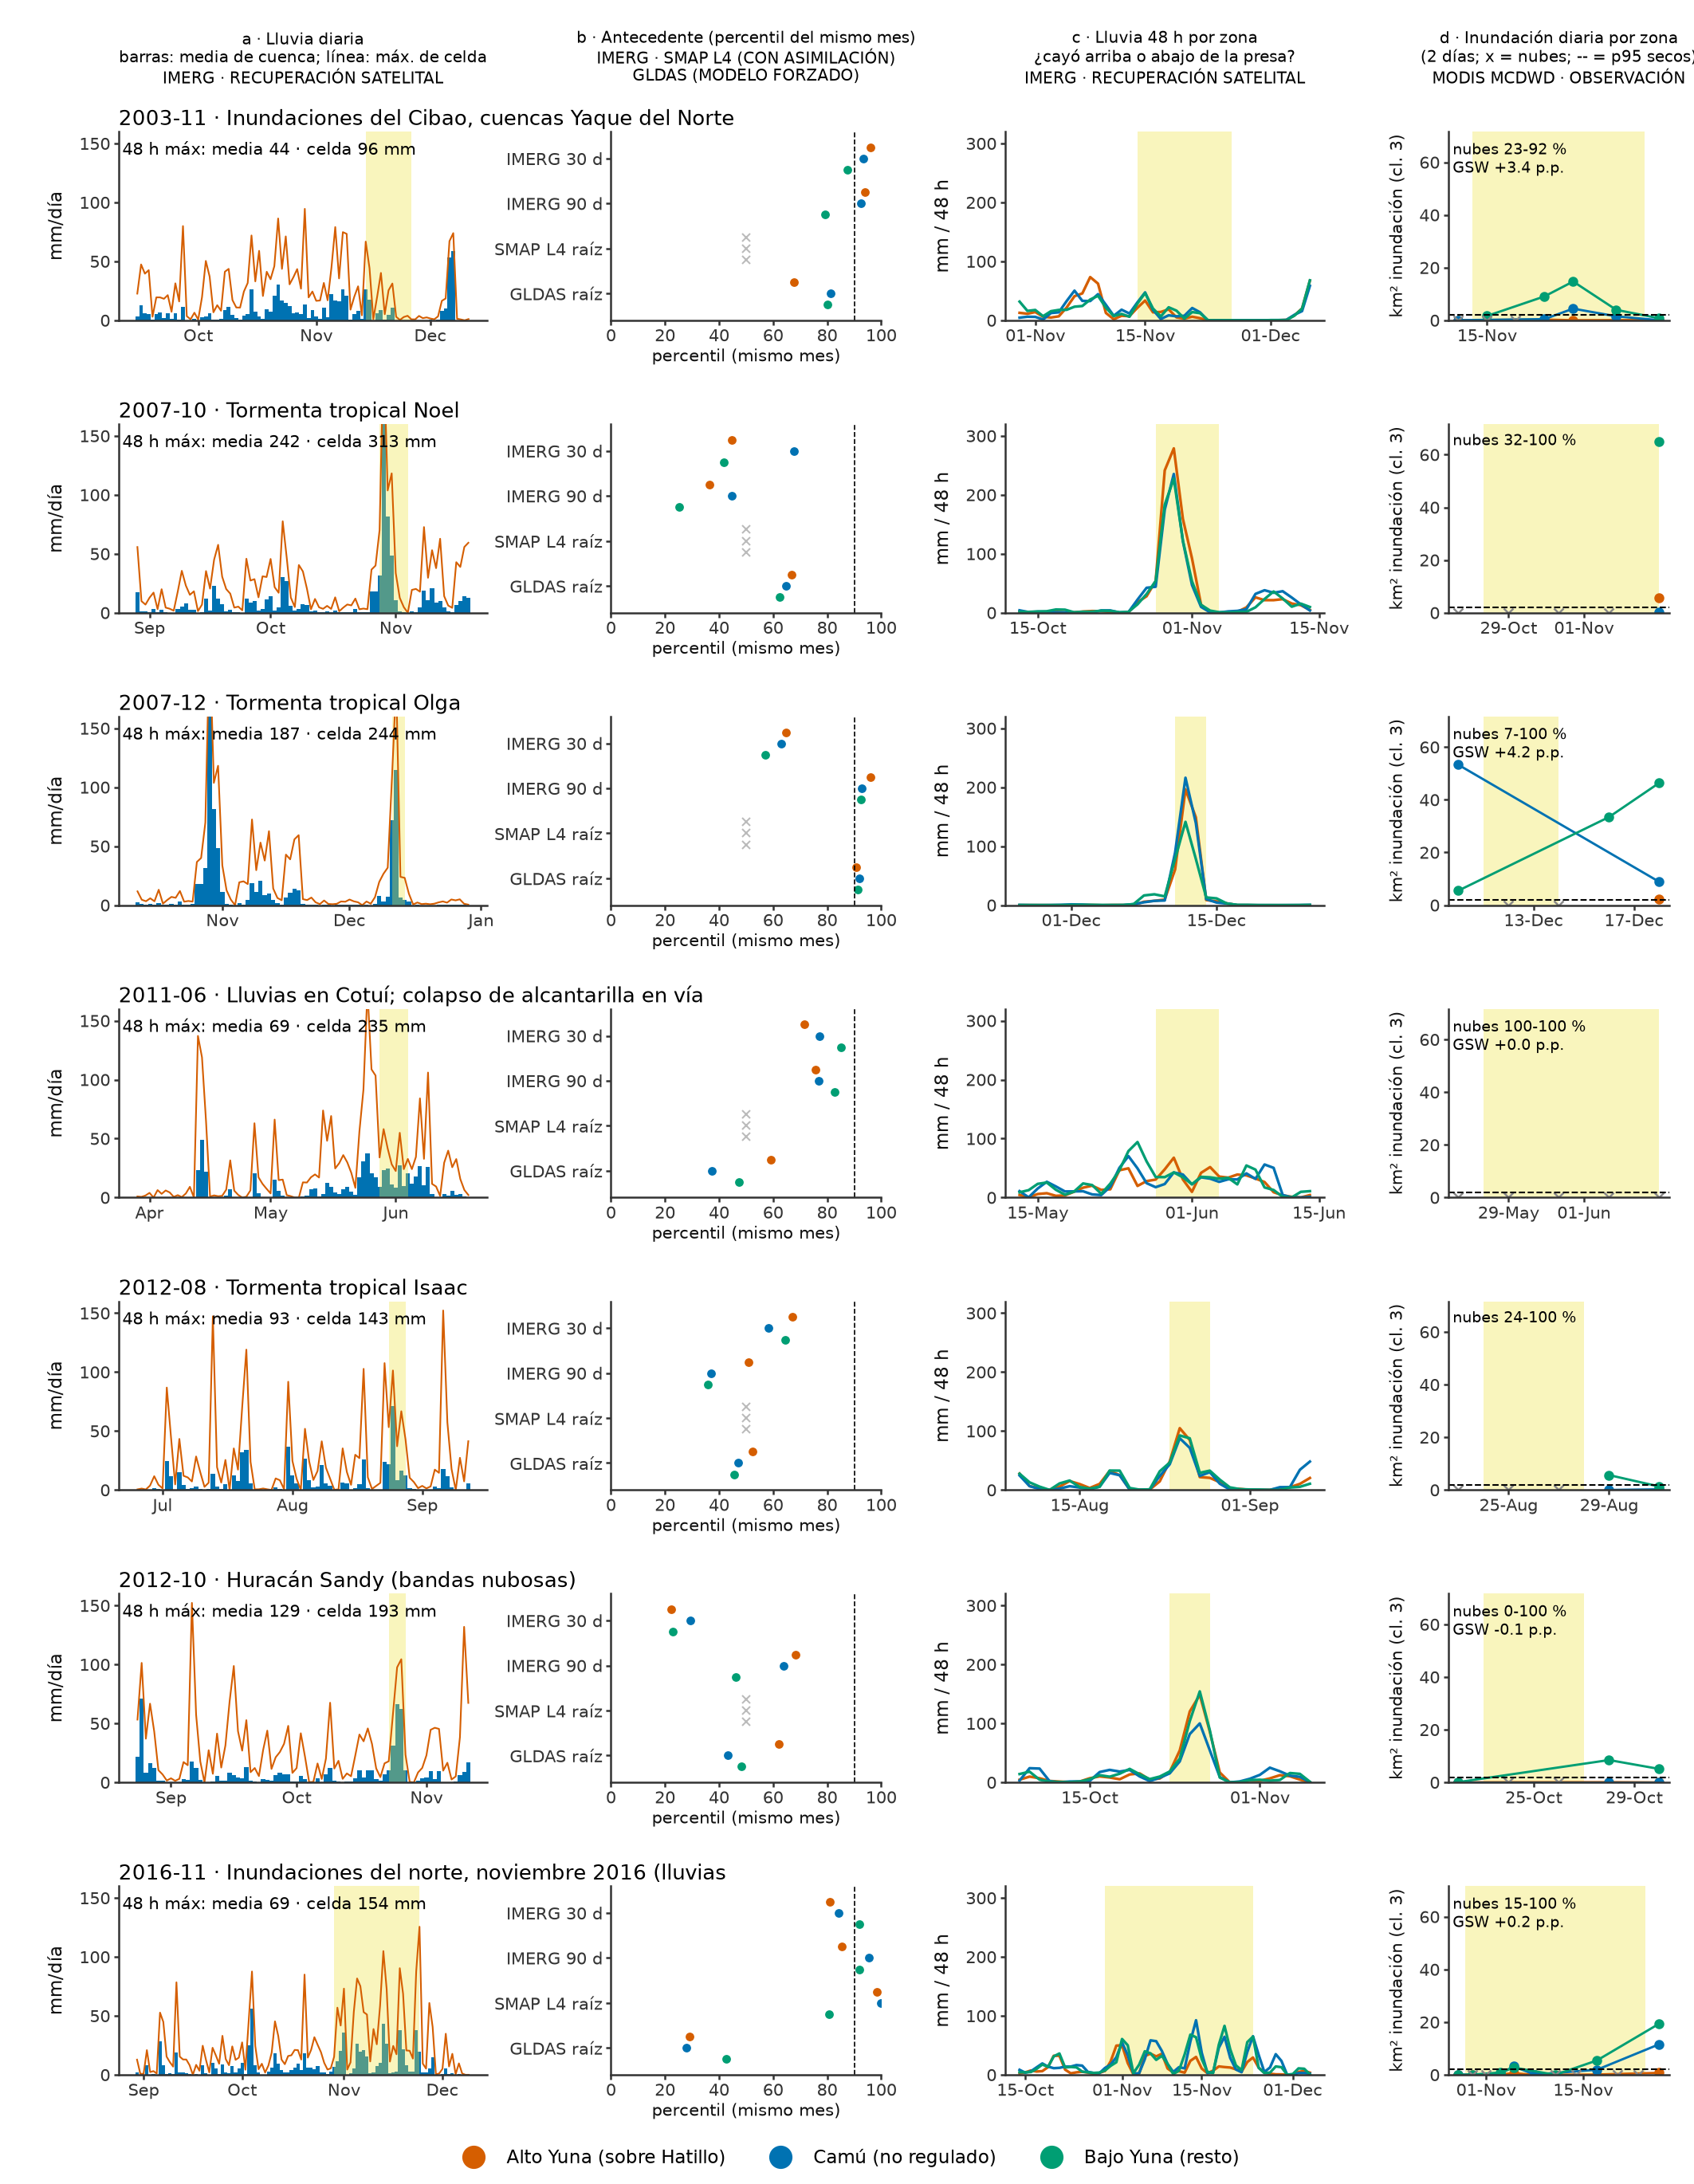

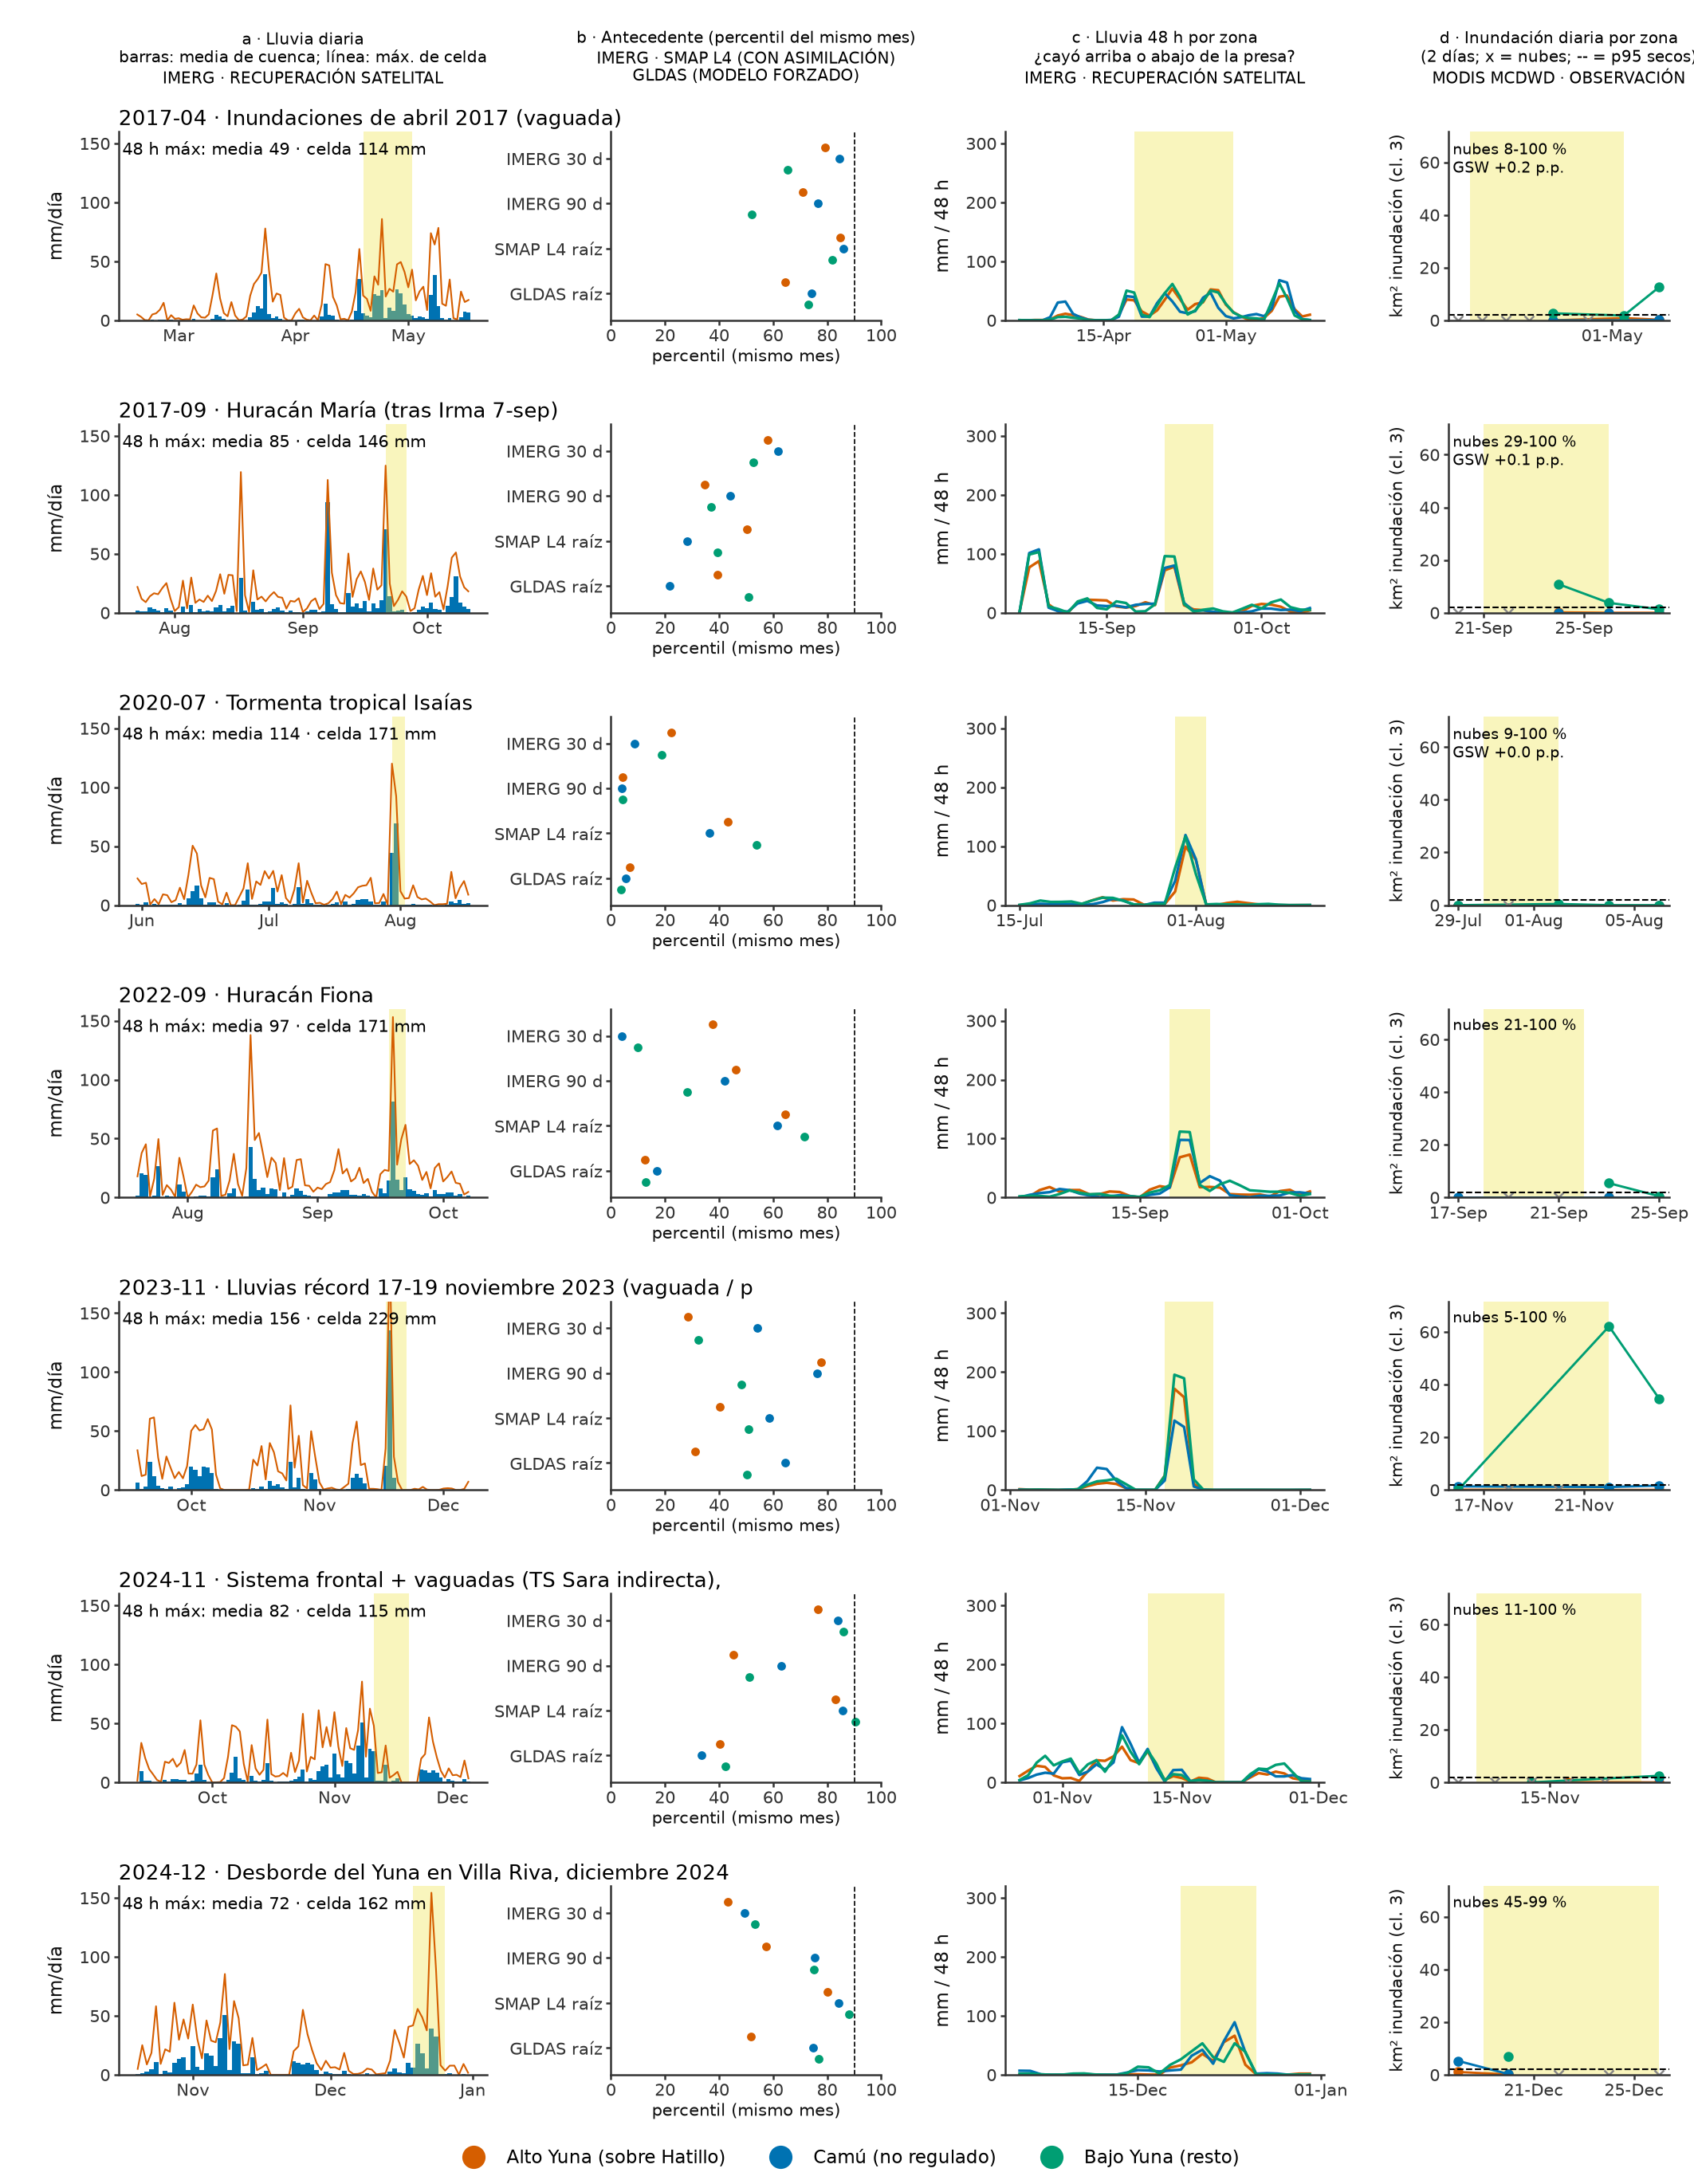

In [13]:
for f in sorted(FIG.glob("fig_y3_paneles_eventos_*.png")):
    display(Image(filename=str(f), width=950))

In [14]:
pd.read_csv(RES / "paneles_eventos.csv").set_index("id").T.head(60)

id,2003-11,2007-10,2007-12,2011-06,2012-08,2012-10,2016-11,2017-04,2017-09,2020-07,2022-09,2023-11,2024-11,2024-12,2025-10,2026-04
nombre,"Inundaciones del Cibao, cuencas Yaque del Norte y Yuna (noviembre 2003)",Tormenta tropical Noel,Tormenta tropical Olga,Lluvias en Cotuí; colapso de alcantarilla en vía a la presa de Hatillo,Tormenta tropical Isaac,Huracán Sandy (bandas nubosas),"Inundaciones del norte, noviembre 2016 (lluvias prolongadas / vaguadas)",Inundaciones de abril 2017 (vaguada),Huracán María (tras Irma 7-sep),Tormenta tropical Isaías,Huracán Fiona,Lluvias récord 17-19 noviembre 2023 (vaguada / potencial ciclón),"Sistema frontal + vaguadas (TS Sara indirecta), noviembre 2024","Desborde del Yuna en Villa Riva, diciembre 2024",Huracán / tormenta Melissa,"Lluvias de abril 2026 (fuera del rango 2001-2025, contexto reciente)"
inicio,2003-11-14,2007-10-28,2007-12-11,2011-05-28,2012-08-24,2012-10-23,2016-10-29,2017-04-19,2017-09-21,2020-07-30,2022-09-18,2023-11-17,2024-11-11,2024-12-19,2025-10-21,2026-04-08
fin,2003-11-26,2007-11-04,2007-12-14,2011-06-04,2012-08-28,2012-10-27,2016-11-24,2017-05-02,2017-09-26,2020-08-02,2022-09-22,2023-11-22,2024-11-20,2024-12-26,2025-10-30,2026-05-02
zona,bajo_yuna,bajo_yuna,bajo_yuna,alto_yuna,cuenca_general,cuenca_general,bajo_yuna,bajo_yuna,bajo_yuna,bajo_yuna,bajo_yuna,bajo_yuna,bajo_yuna,bajo_yuna,bajo_yuna,cuenca_general
confianza,alta,alta,alta,media,media,baja,alta,alta,alta,media,alta,alta,media,media,baja,alta
r48_max_yuna,43.995083,242.414034,186.757286,68.561788,93.151192,128.973753,69.017731,49.35796,84.787816,113.663312,96.553931,155.68725,81.595386,72.072918,NaN,NaN
r72_max_yuna,44.930506,290.929308,193.947472,88.80855,116.961125,160.28791,79.034219,69.227773,95.663266,113.952475,111.363058,166.243186,89.072471,77.699864,NaN,NaN
ant30_yuna_mm,333.353936,159.84641,105.17455,228.238705,174.083236,113.249141,232.707358,118.585821,190.162967,80.376786,102.886585,125.101538,260.087493,75.240147,NaN,NaN
ant30_yuna_pct,93.472222,57.930108,61.424731,77.284946,61.827957,20.564516,87.903226,78.333333,57.361111,15.188172,12.222222,40.694444,82.777778,50.672043,NaN,NaN
ant60_yuna_mm,450.742903,289.732183,525.932973,334.9704,352.13491,353.569775,360.052844,134.507024,296.942411,155.568233,312.131594,294.496414,353.628108,385.016416,NaN,NaN


In [15]:
pd.read_csv(RES / "datos_suficientes_por_evento.csv")

,id,zona,usable_backtest,motivo,IMERG_antecedente_y_evento,SMAP_L4,GEOGLOWS,GSW_mes_validos_llanura,GSW_observa,mcdwd_observa,mcdwd_n_obs_yuna,mcdwd_insuf_min_yuna
0,2003-11,bajo_yuna,True,NaN,True,False,True,0.701101,True,True,4.0,0.230409
1,2007-10,bajo_yuna,True,NaN,True,False,True,0.892138,True,True,1.0,0.324516
2,2007-12,bajo_yuna,True,NaN,True,False,True,0.953260,True,True,3.0,0.073375
3,2011-06,alto_yuna,True,NaN,True,False,True,0.658442,True,NaN,0.0,0.995317
4,2012-08,cuenca_general,True,NaN,True,False,True,0.000000,False,True,2.0,0.242058
5,2012-10,cuenca_general,True,NaN,True,False,True,0.818881,True,True,3.0,0.001906
6,2016-11,bajo_yuna,True,NaN,True,True,True,0.985596,True,True,6.0,0.147291
7,2017-04,bajo_yuna,True,NaN,True,True,True,0.999988,True,True,3.0,0.077964
8,2017-09,bajo_yuna,True,NaN,True,True,True,0.850225,True,True,3.0,0.294677
9,2020-07,bajo_yuna,True,NaN,True,True,True,0.926835,True,False,4.0,0.086012


## 5 · Backtest de disparadores (n pequeño)

Calibración 2001-2015, prueba 2016-2024; IC 95 % por bootstrap de años. FAR es cota superior: el catálogo de prensa es incompleto.

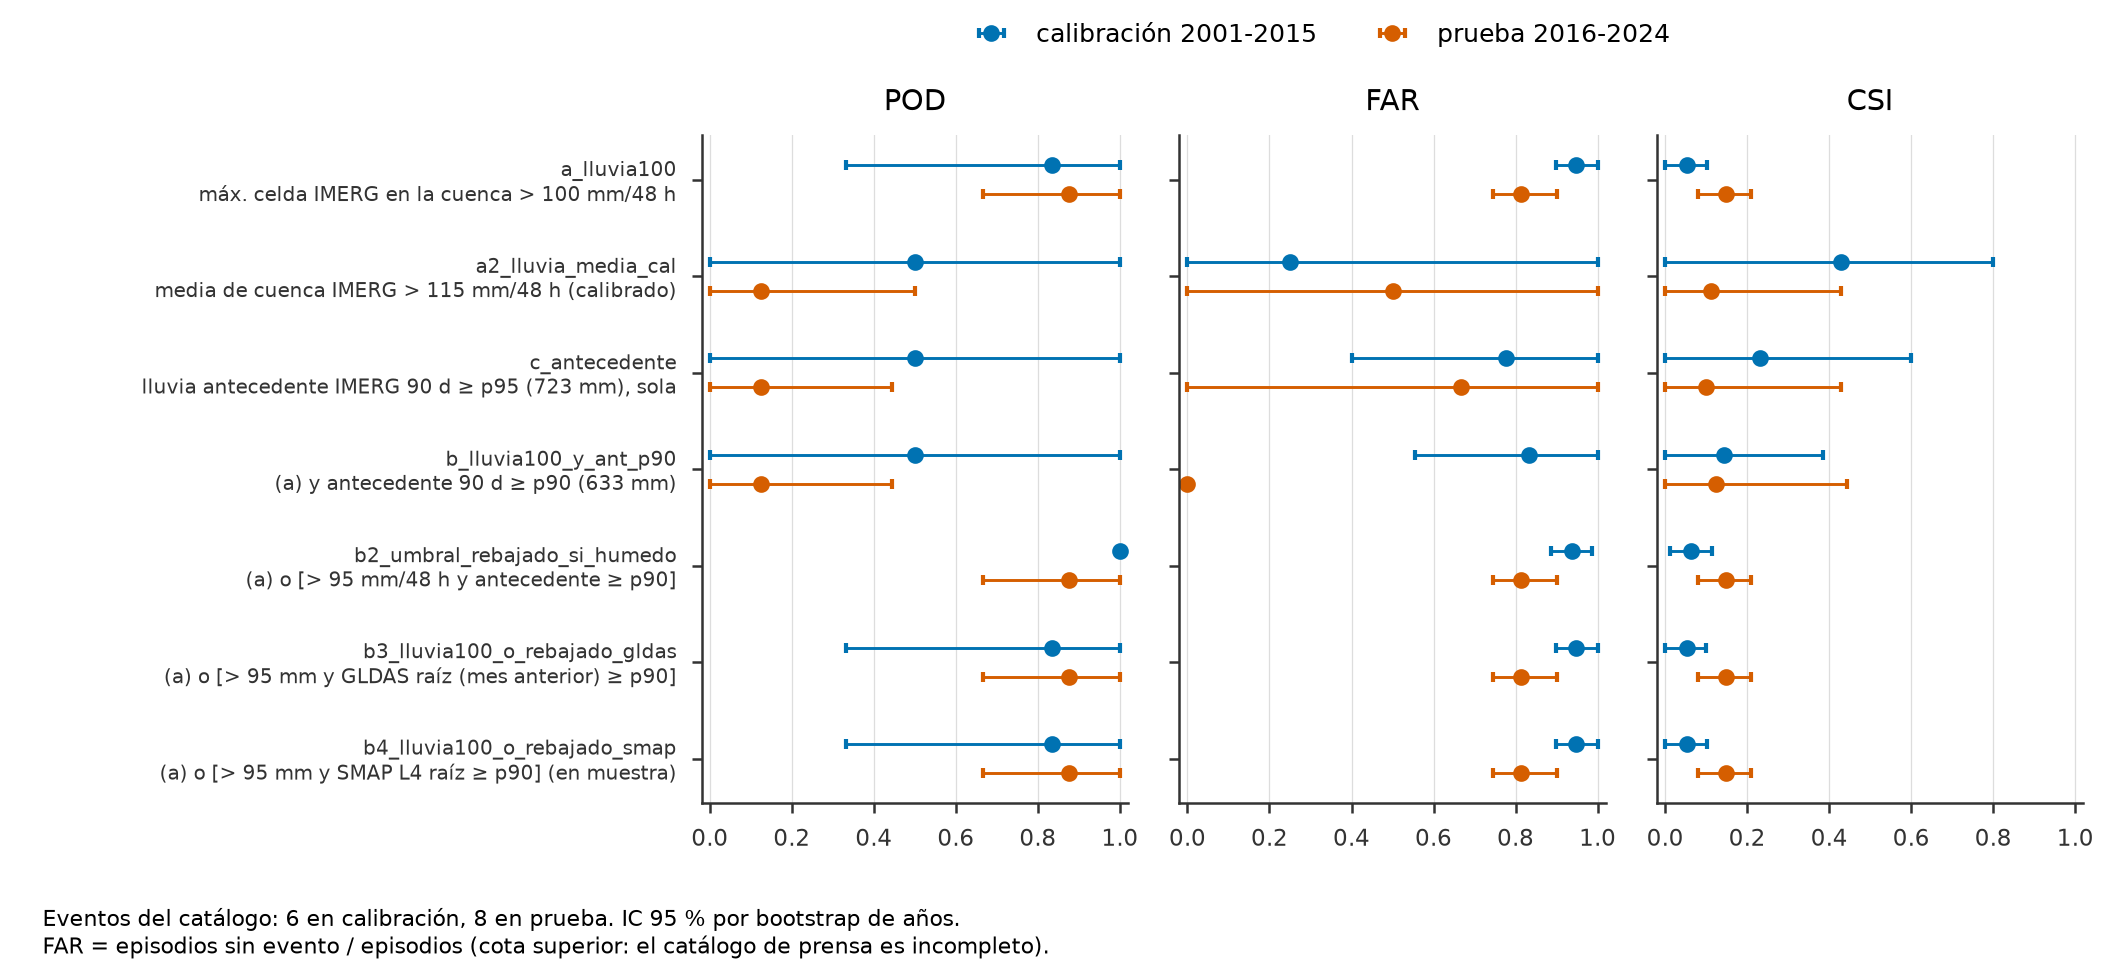

In [16]:
fig("fig_y4_backtest_disparadores")

In [17]:
bt = pd.read_csv(RES / "backtest_disparadores.csv")
bt[["disparador", "periodo", "eventos", "aciertos", "fallos", "episodios", "falsas_alarmas", "POD", "POD_ic95", "FAR", "FAR_ic95", "CSI", "CSI_ic95"]]

,disparador,periodo,eventos,aciertos,fallos,episodios,falsas_alarmas,POD,POD_ic95,FAR,FAR_ic95,CSI,CSI_ic95
0,a_lluvia100,calibración 2001-2015,6,5,1,94,89,0.833333,"(0.3333333333333333, 1.0)",0.946809,"(0.8974226804123712, 1.0)",0.052632,"(0.0, 0.10112359550561797)"
1,a_lluvia100,prueba 2016-2024,8,7,1,48,39,0.875000,"(0.6666666666666666, 1.0)",0.812500,"(0.7441711389385808, 0.9000609756097558)",0.148936,"(0.07889676113360324, 0.20969864176570446)"
2,a2_lluvia_media_cal,calibración 2001-2015,6,3,3,4,1,0.500000,"(0.0, 1.0)",0.250000,"(0.0, 1.0)",0.428571,"(0.0, 0.8)"
3,a2_lluvia_media_cal,prueba 2016-2024,8,1,7,2,1,0.125000,"(0.0, 0.5)",0.500000,"(0.0, 1.0)",0.111111,"(0.0, 0.42857142857142855)"
4,c_antecedente,calibración 2001-2015,6,3,3,9,7,0.500000,"(0.0, 1.0)",0.777778,"(0.4, 1.0)",0.230769,"(0.0, 0.6)"
5,c_antecedente,prueba 2016-2024,8,1,7,3,2,0.125000,"(0.0, 0.4444444444444444)",0.666667,"(0.0, 1.0)",0.100000,"(0.0, 0.42857142857142855)"
6,b_lluvia100_y_ant_p90,calibración 2001-2015,6,3,3,18,15,0.500000,"(0.0, 1.0)",0.833333,"(0.5555555555555556, 1.0)",0.142857,"(0.0, 0.38461538461538464)"
7,b_lluvia100_y_ant_p90,prueba 2016-2024,8,1,7,3,0,0.125000,"(0.0, 0.4444444444444444)",0.000000,"(0.0, 0.0)",0.125000,"(0.0, 0.4444444444444444)"
8,b2_umbral_rebajado_si_humedo,calibración 2001-2015,6,6,0,95,89,1.000000,"(1.0, 1.0)",0.936842,"(0.8863636363636364, 0.987012987012987)",0.063158,"(0.012987012987012988, 0.11363636363636363)"
9,b2_umbral_rebajado_si_humedo,prueba 2016-2024,8,7,1,48,39,0.875000,"(0.6666666666666666, 1.0)",0.812500,"(0.7441711389385808, 0.9000609756097558)",0.148936,"(0.07889676113360324, 0.20969864176570446)"


## 6 · La presa como factor de confusión

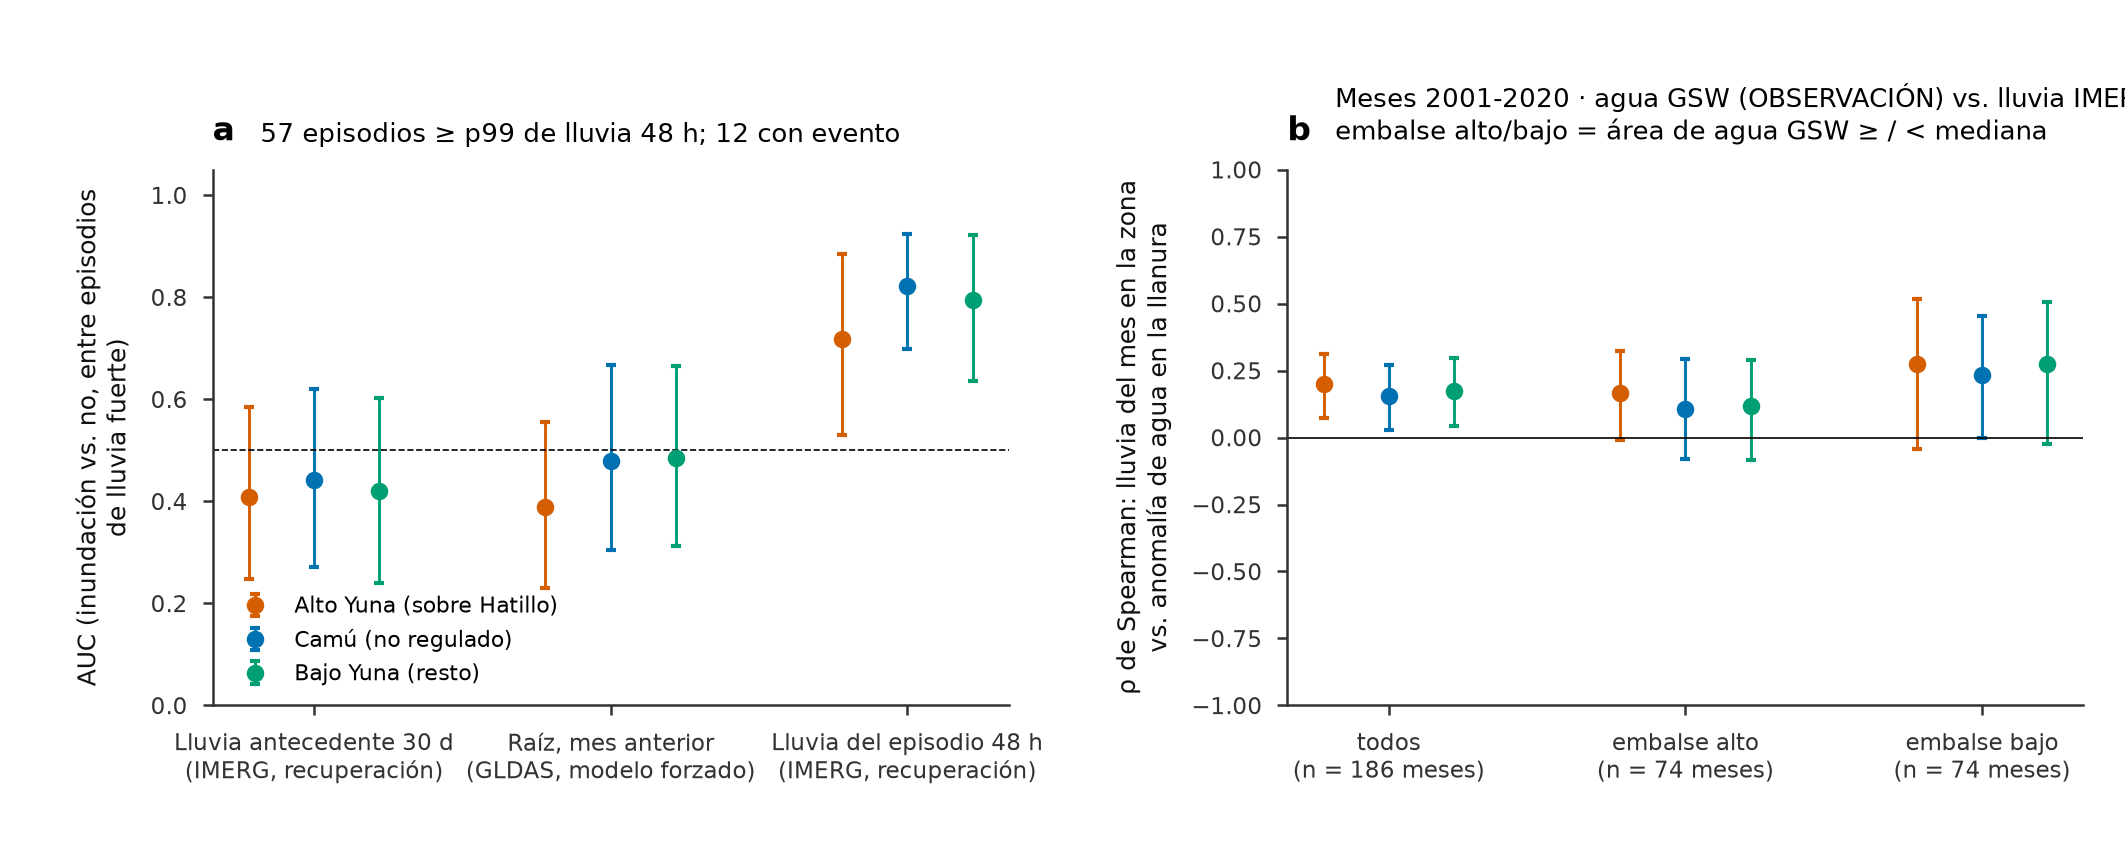

In [18]:
fig("fig_y5_presa_confusor")

In [19]:
r = json.loads((RES / "analisis_resumen.json").read_text(encoding="utf-8"))
print(json.dumps(r, ensure_ascii=False, indent=1)[:4000])

{
 "backtest_info": {
  "a2_umbral": 115.0,
  "c": {
   "n_dias": 90,
   "percentil": 0.95,
   "umbral_mm": 722.7656214307216
  },
  "antecedente_p90_mm": 633.0667066505939,
  "b2_umbral_bajo": 95.0
 },
 "presa_auc": {
  "umbral_r48max_p99_mm": 135.40299316406268,
  "n_episodios": 57,
  "n_con_inundacion": 12,
  "AUC_ant30_pct_alto_hatillo": 0.4083333333333333,
  "AUC_ant30_pct_alto_hatillo_ic95": [
   0.24814814814814815,
   0.5852314814814812
  ],
  "AUC_ant30_pct_camu": 0.4425925925925926,
  "AUC_ant30_pct_camu_ic95": [
   0.27037037037037037,
   0.6204166666666664
  ],
  "AUC_ant30_pct_bajo_yuna": 0.41944444444444445,
  "AUC_ant30_pct_bajo_yuna_ic95": [
   0.24074074074074073,
   0.6018518518518519
  ],
  "dAUC_ant30_pct_alto_menos_camu": -0.03425925925925927,
  "dAUC_ant30_pct_alto_menos_camu_ic95": [
   -0.1396904761904762,
   0.06719367588932806
  ],
  "AUC_gldas_z_alto_hatillo": 0.3888888888888889,
  "AUC_gldas_z_alto_hatillo_ic95": [
   0.22962962962962963,
   0.55555555555555

In [20]:
pd.read_csv(RES / "presa_correlaciones_mensuales.csv")

,estado_embalse,zona_antecedente,variable,n_meses,rho,ic95
0,todos,alto_hatillo,lluvia_mes,186,0.198272,"[0.07137967344678557, 0.31139506462520655]"
1,todos,alto_hatillo,gldas_z,186,-0.049619,"[-0.19652395780143309, 0.10906105131753968]"
2,todos,camu,lluvia_mes,186,0.155204,"[0.02734666226218538, 0.27211233558272135]"
3,todos,camu,gldas_z,186,0.008940,"[-0.1398925964262835, 0.18835708258250589]"
4,todos,bajo_yuna,lluvia_mes,186,0.173922,"[0.04215519695737769, 0.29818663047964733]"
5,todos,bajo_yuna,gldas_z,186,0.069150,"[-0.09812122423727099, 0.239567141181893]"
6,embalse_alto,alto_hatillo,lluvia_mes,74,0.167773,"[-0.010647103639829349, 0.3220272160708552]"
7,embalse_alto,alto_hatillo,gldas_z,74,-0.074867,"[-0.32437404343839954, 0.20142135538248024]"
8,embalse_alto,camu,lluvia_mes,74,0.105095,"[-0.0818425953963389, 0.2918309215004499]"
9,embalse_alto,camu,gldas_z,74,0.016351,"[-0.2448412512888726, 0.29829246142466415]"


## Límites

- n de eventos pequeño: los IC son anchos y casi nada distingue un disparador de otro.
- IMERG, SMAP L4 y CHIRPS comparten insumos (pluviómetros GPCC/GTS; SMAP L4 ajusta su lluvia a IMERG): su acuerdo no es validación independiente.
- GEOGLOWS no son aforos ni representa la operación de Hatillo.
- No hay series públicas de nivel/descarga de Hatillo: el área GSW es un sustituto mensual con huecos por nubes.